# CA4 - Telecom Customer Churn Classification

## Group 3 Members
- Stig Espen Paulsberg
- Vinicius Millan
- Zaur Kambiev


## 1. Imports

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import confusion_matrix, f1_score, make_scorer, precision_score, recall_score
from sklearn.metrics.pairwise import laplacian_kernel
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

## 2. Reading data

In [7]:
df = pd.read_csv("dat-200-ca-4-h-2026/trainCA4DAT200.csv", index_col="CustomerId")
df.head()

,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
CustomerId,,,,,,,,,,,,,,,,,,,,
952920,NJ,87,510,no,no,0,223.2,109,37.94,127.5,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
895150,RI,114,510,no,yes,28,225.8,94,38.39,193.0,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
636987,ND,55,415,no,no,0,180.1,77,30.62,235.5,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
538188,DC,100,510,yes,no,0,68.5,110,11.65,337.1,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
947531,AL,74,408,no,yes,46,277.7,109,47.21,270.0,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


## 3. Data exploration & visualisation

* Check missing and duplicated values.

In [8]:
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicated rows: {df.duplicated().sum()}")

Missing values: 0
Duplicated rows: 0


### 3.a Categorical variables - overview

* Check the number of unique values in the categorical features.

In [9]:
raw_categorical = ["State", "AreaCode", "InternationalPlan", "VoiceMailPlan"]

print(
    df[raw_categorical]
    .nunique()
    .to_string()
)

State                51
AreaCode              3
InternationalPlan     2
VoiceMailPlan         2


* How is `State` connected with the churn rate?

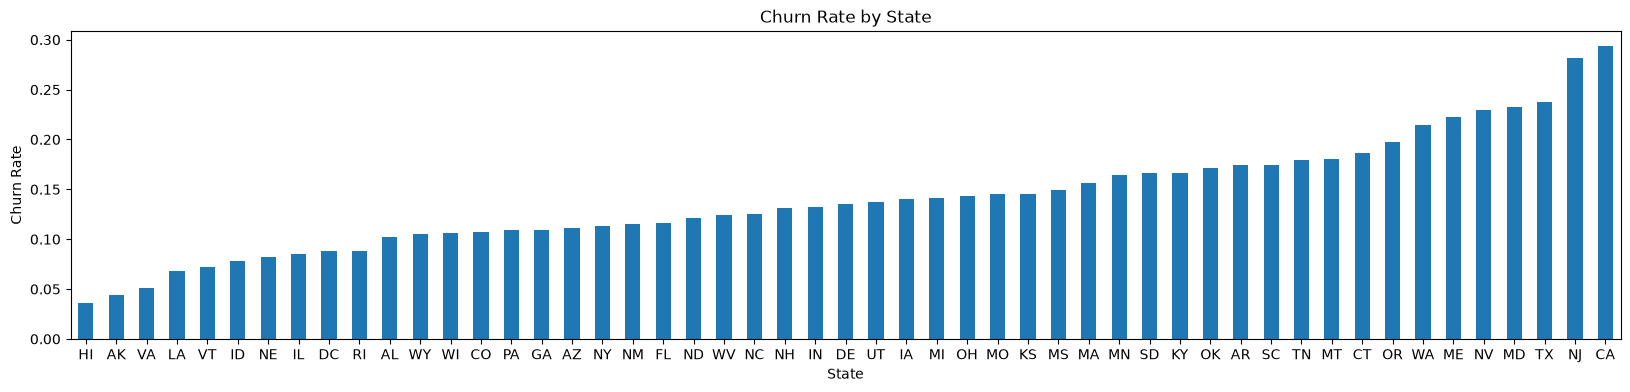

In [10]:
plt.figure(figsize=(20, 4))

(
    df.groupby("State")
    ["Churn"].mean()
    .sort_values()
    .plot.bar()
)

plt.xlabel("State")
plt.tick_params(axis="x", rotation=0)
plt.ylabel("Churn Rate")
plt.title("Churn Rate by State")
plt.show()

* It seems that `State` is a good predictor of `Churn`, with the churn rate varying from 4% to 30% across states. However, this could also simply reflect the characteristics of the people living in those states.

* How is `AreaCode` connected with the churn rate?

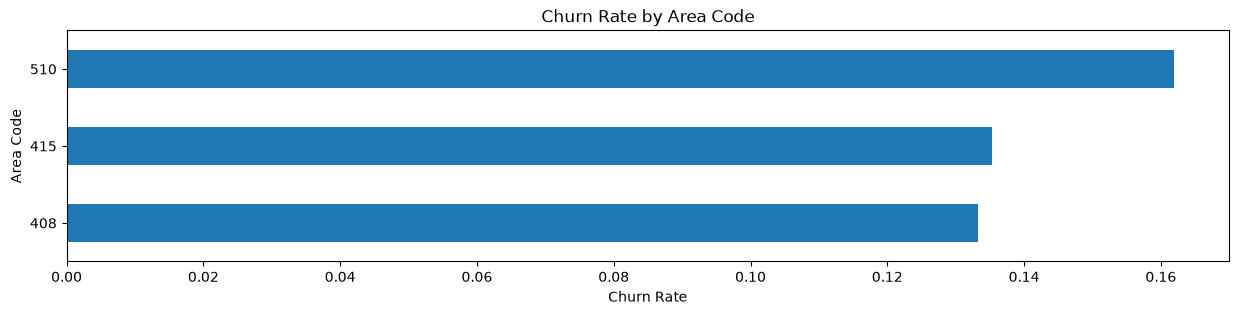

In [11]:
plt.figure(figsize=(15, 3))

(
    df.groupby("AreaCode")
    ["Churn"].mean()
    .plot.barh()
)

plt.xlabel("Churn Rate")
plt.ylabel("Area Code")
plt.title("Churn Rate by Area Code")
plt.show()

* `AreaCode` has no noticeable impact on the churn rate.

* How is `InternationalPlan` connected with the churn rate?

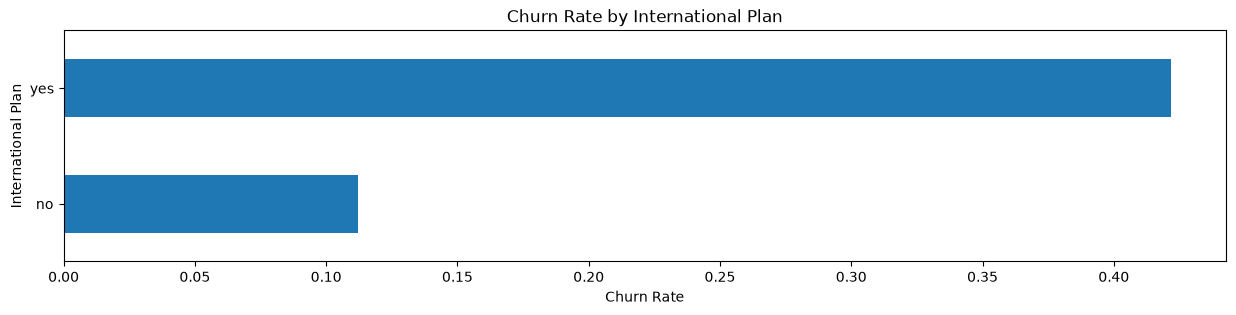

In [12]:
plt.figure(figsize=(15, 3))

(
    df.groupby("InternationalPlan")
    ["Churn"].mean()
    .plot.barh()
)

plt.xlabel("Churn Rate")
plt.ylabel("International Plan")
plt.title("Churn Rate by International Plan")
plt.show()

* Here we see a large difference in churn rates. Let's compare customers with different levels of international charges.

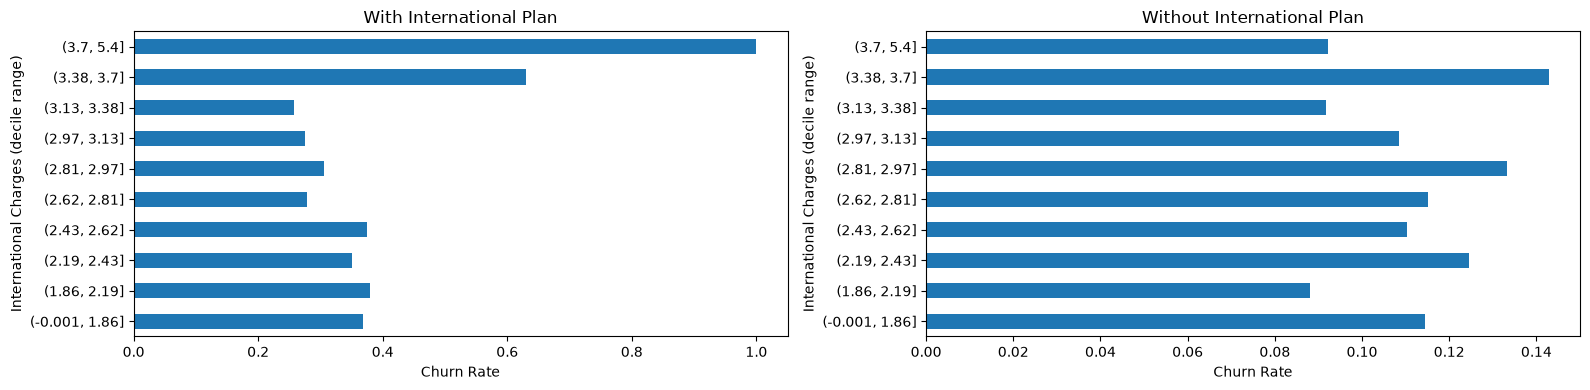

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

for value, ax in zip(["yes", "no"], axes):
    (
        df[df["InternationalPlan"] == value]
        .groupby(pd.qcut(df["IntlCharge"], q=10))
        ["Churn"].mean()
        .plot.barh(ax=ax)
    )
    ax.set_xlabel("Churn Rate")
    ax.set_ylabel("International Charges (decile range)")
    ax.set_title(
        "With International Plan" if value == "yes" else "Without International Plan"
    )

plt.tight_layout()    
plt.show()

* Among customers without an international plan, churn stays roughly the same no matter how high their international charges are.

* Among customers with an international plan, churn rises with charges: every customer in the top 10% of international charges churned.

* How is `VoiceMailPlan` connected with the churn rate?

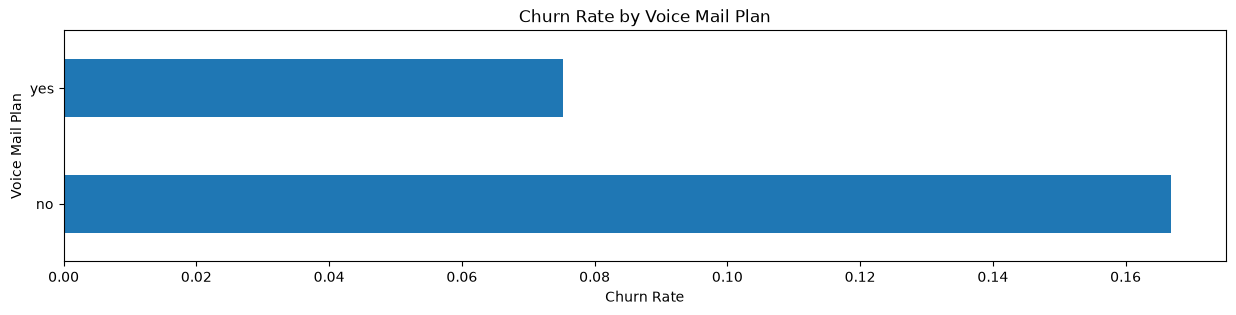

In [14]:
plt.figure(figsize=(15, 3))

(
    df.groupby("VoiceMailPlan")
    ["Churn"].mean()
    .plot.barh()
)

plt.xlabel("Churn Rate")
plt.ylabel("Voice Mail Plan")
plt.title("Churn Rate by Voice Mail Plan")
plt.show()

* Customers with a voicemail plan churn noticeably less often.

* Let's encode the binary features `InternationalPlan` and `VoiceMailPlan` as 0 and 1 so that we can include them in the correlation heatmap.

In [15]:
def encode_binary_features(df):
    new_df = df.copy()
    new_df["InternationalPlan"] = (df.InternationalPlan == 'yes').astype(float)
    new_df["VoiceMailPlan"] = (df.VoiceMailPlan == 'yes').astype(float)
    return new_df

df = encode_binary_features(df)

### 3.b Numerical variables - overview

* Let's build a correlation heatmap.

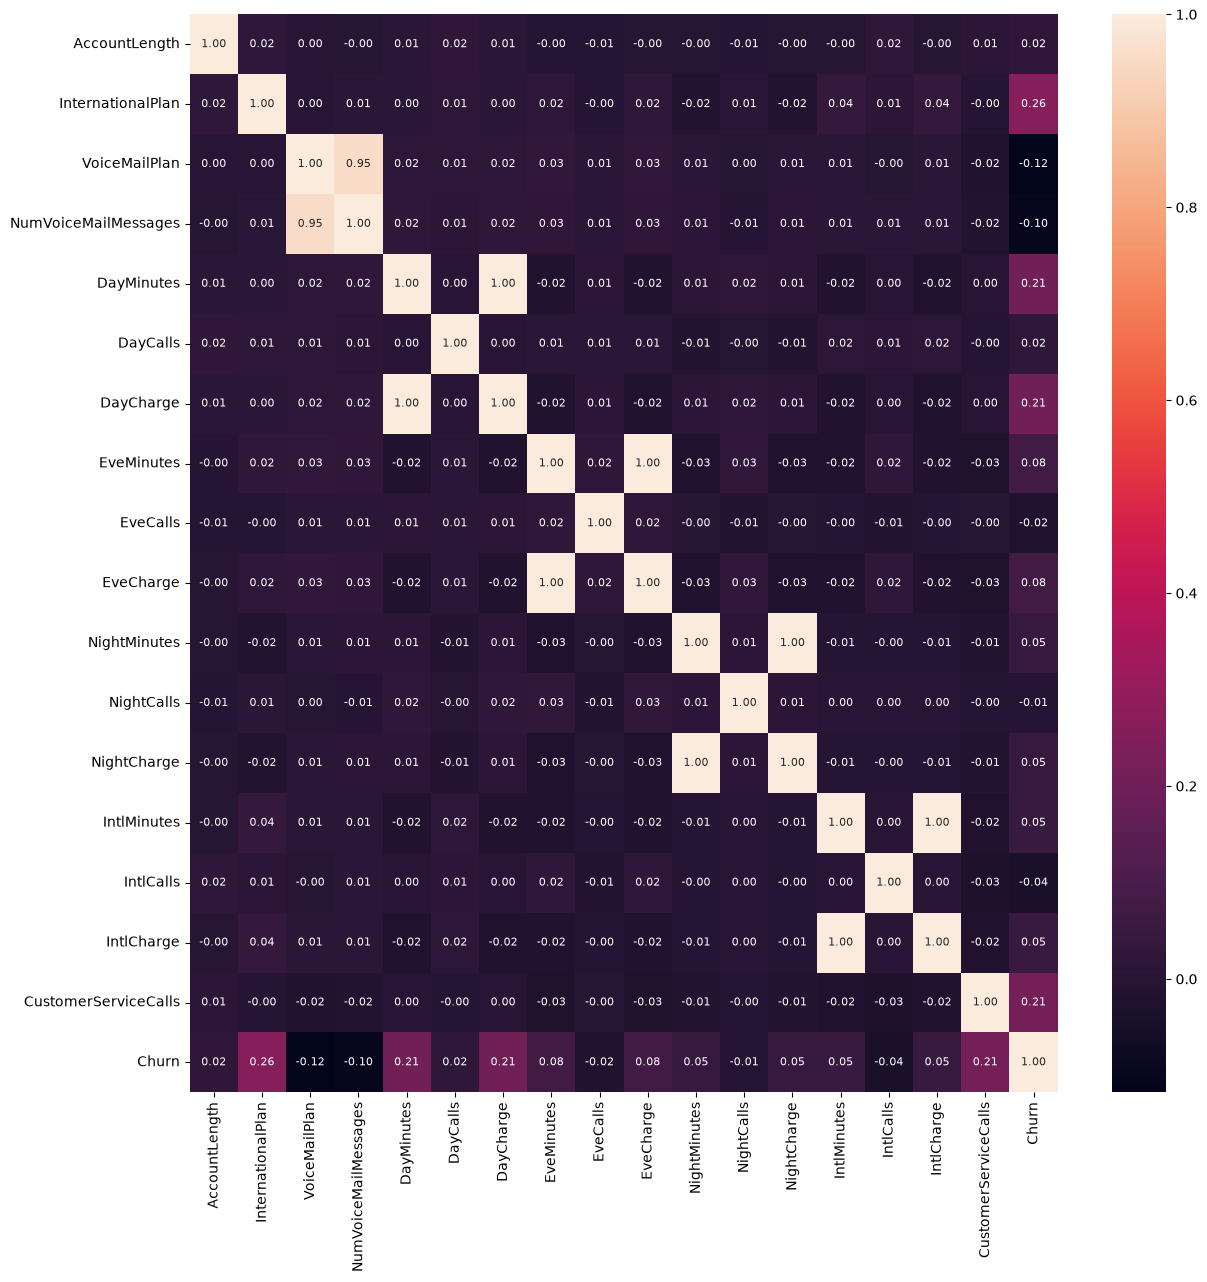

In [16]:
heatmap_columns = df.columns.drop(["State", "AreaCode"])

plt.figure(figsize=(14, 14))
sns.heatmap(
    df[heatmap_columns].corr(),
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8}
)
plt.show()

* Here we see that `DayMinutes`, `EveMinutes`, `NightMinutes`, and `IntlMinutes` are perfectly correlated with the corresponding charges (correlation = 1). This suggests that each charge is simply the number of minutes multiplied by a fixed per-minute rate. Since these pairs carry the same information, we can drop the charge columns to avoid redundant features.

* We also see that `CustomerServiceCalls` appears to be related to `Churn`. Let's look at how the churn rate changes with the number of service calls.

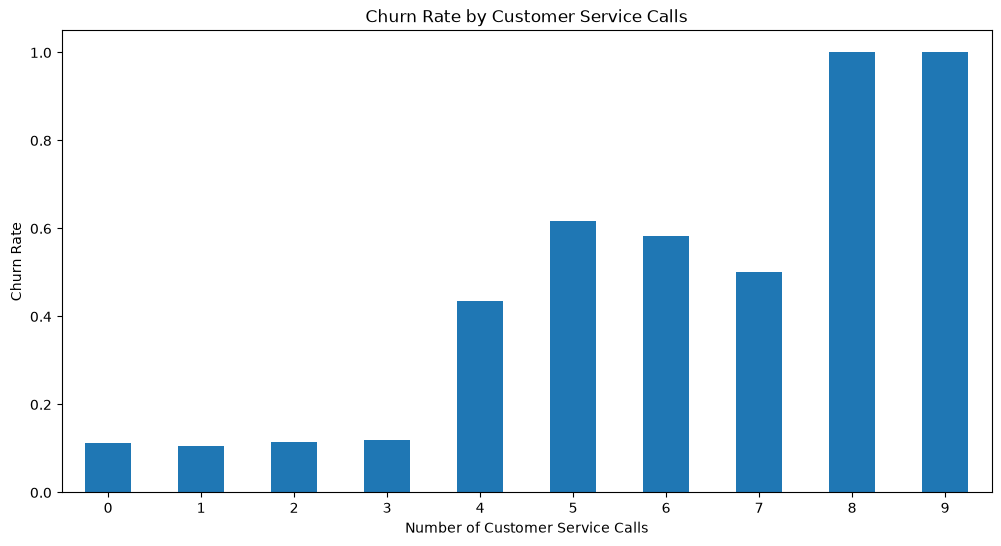

In [17]:
plt.figure(figsize=(12, 6))

(
    df.groupby("CustomerServiceCalls")
    ["Churn"].mean()
    .plot.bar()
)

plt.xlabel("Number of Customer Service Calls")
plt.tick_params(axis="x", rotation=0)
plt.ylabel("Churn Rate")
plt.title("Churn Rate by Customer Service Calls")
plt.show()

* There are two large jumps in churn: from 3 to 4 service calls, the churn rate rises from about 10% to 40%, and from 7 to 8 calls, it rises from about 50% to 100%.

* Let's also check whether other numerical features contain outliers by making boxplots.

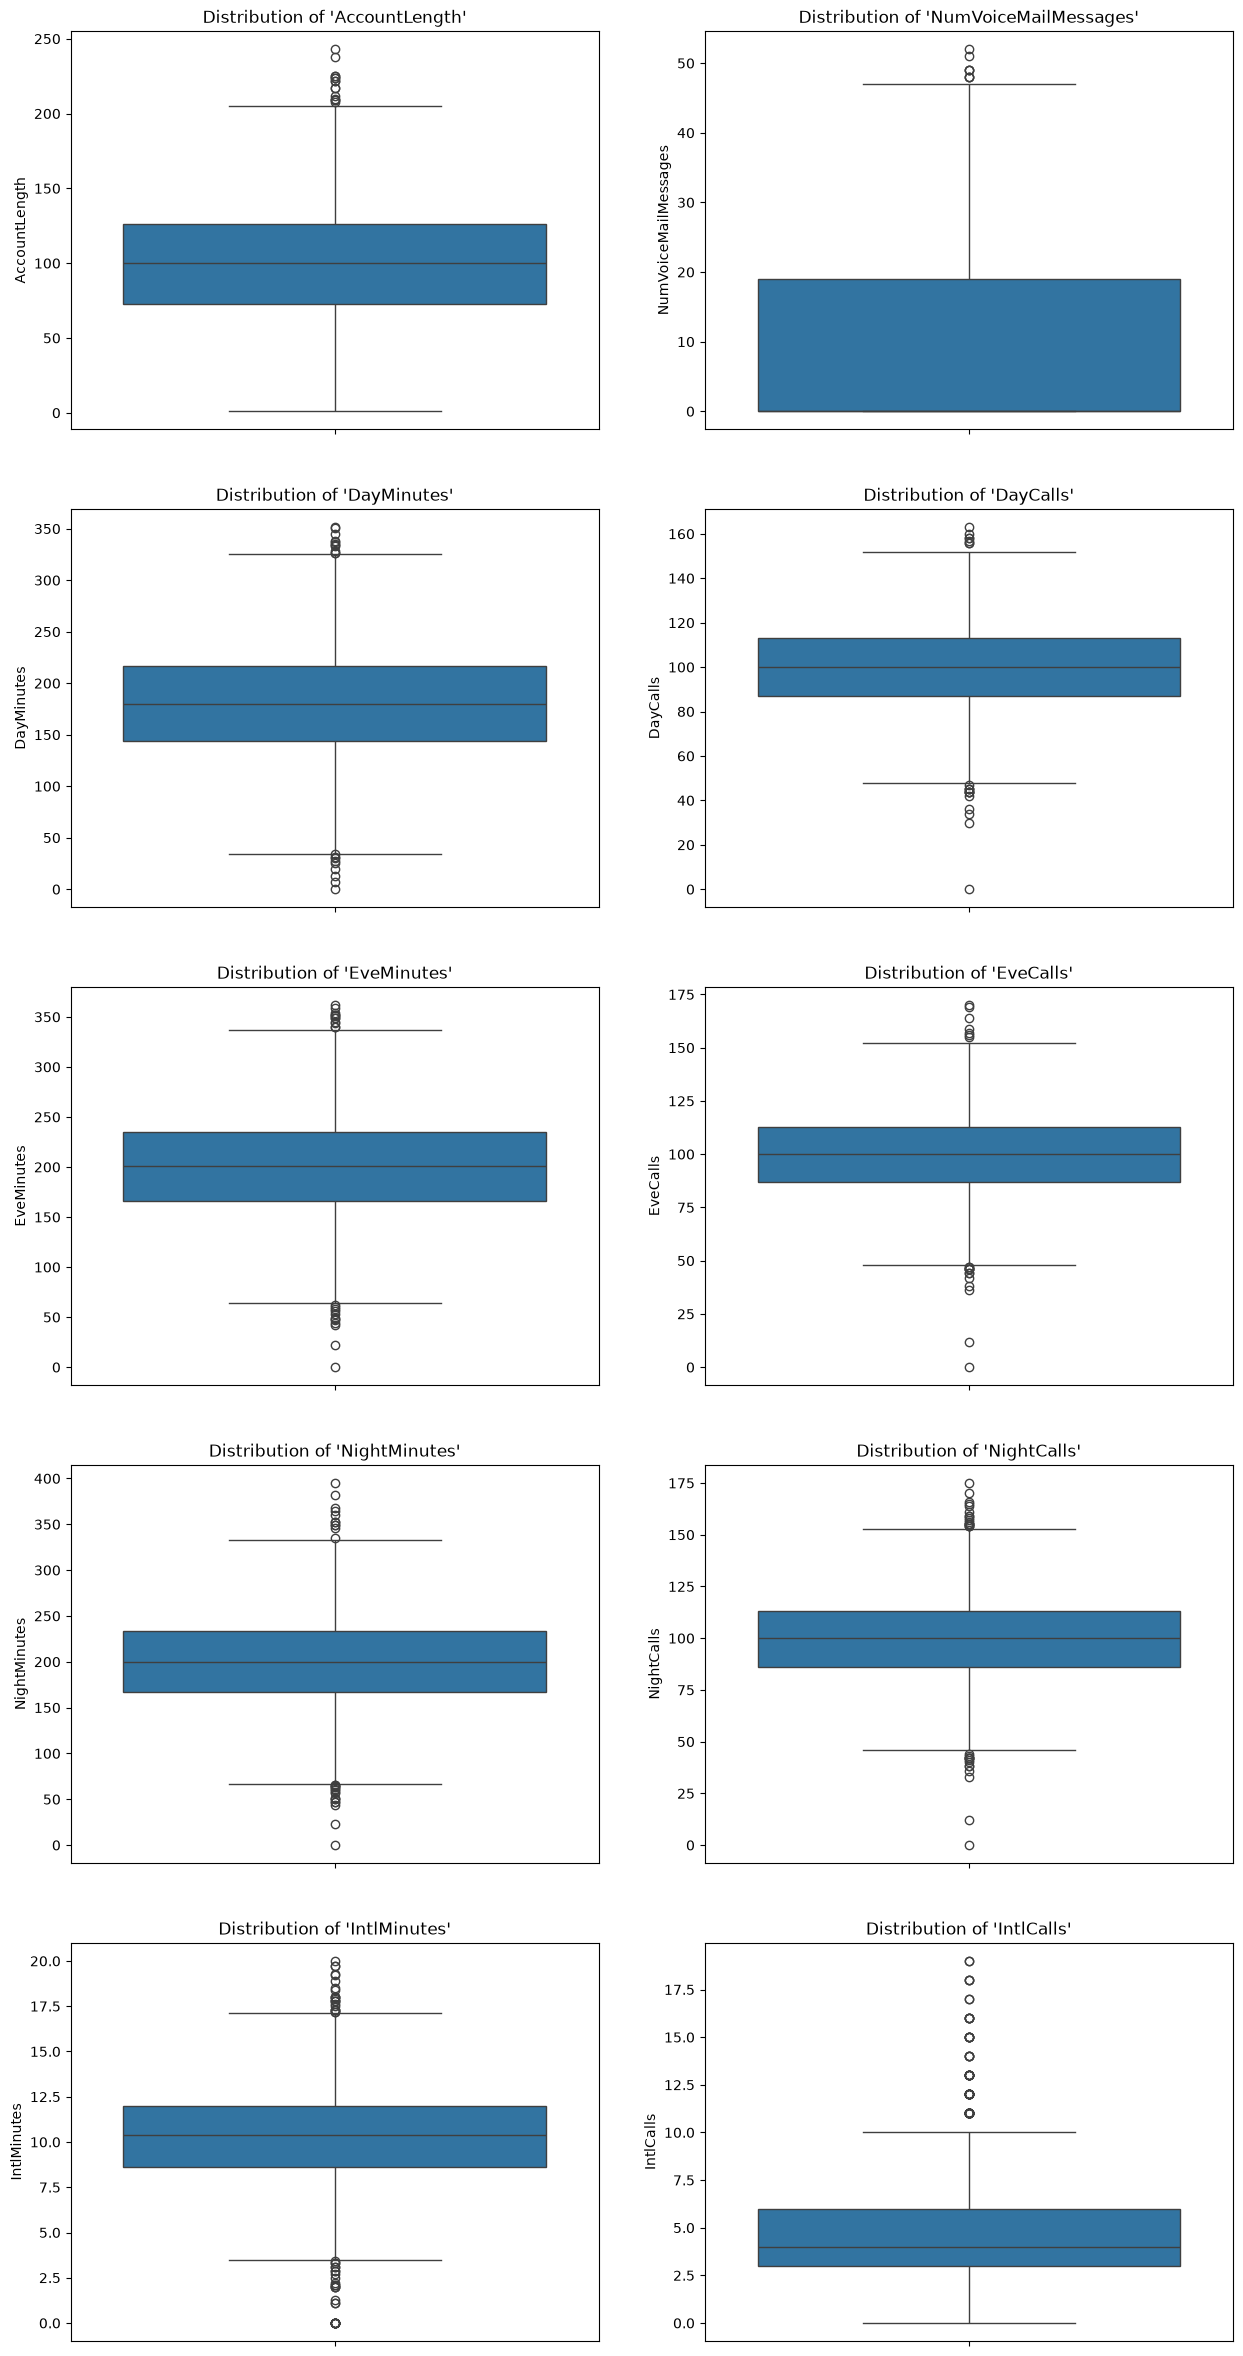

In [18]:
features_to_plot = [
    'AccountLength', 'NumVoiceMailMessages', 'DayMinutes',
    'DayCalls', 'EveMinutes', 'EveCalls', 'NightMinutes', 
    'NightCalls', 'IntlMinutes', 'IntlCalls'
]

fig, axes = plt.subplots(5, 2, figsize=(15, 30))

for feature, ax in zip(features_to_plot, axes.flatten()):

    sns.boxplot(data=df[feature], ax=ax)
    
    ax.set_title(f"Distribution of '{feature}'")

plt.show()

* Some values fall outside the typical range, but none of them look like data errors.

* Most features are roughly symmetric, except `NumVoiceMailMessages`. Let's plot it only for customers with a voicemail plan.

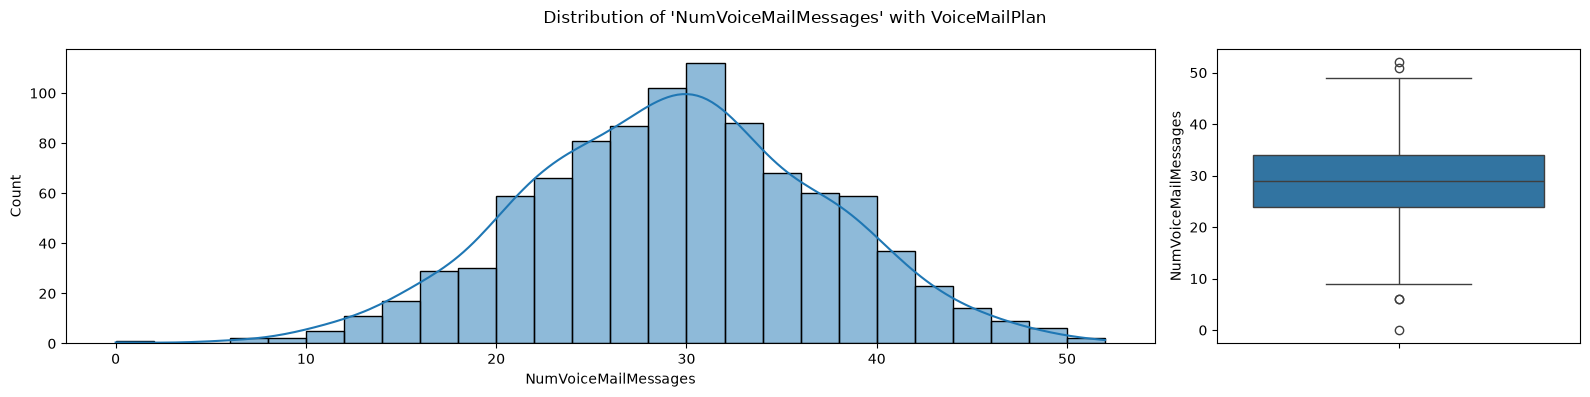

In [19]:
voice_messages_with_plan = df[df["VoiceMailPlan"] == 1.0]["NumVoiceMailMessages"]
voice_messages_with_plan

fig, axes = plt.subplots(
    1, 2, 
    figsize=(16, 4), 
    gridspec_kw={'width_ratios': [3, 1]} # ratio of graphs
    )

sns.histplot(
    data=voice_messages_with_plan,
    ax=axes[0], 
    kde=True  # add a smooth line
)

sns.boxplot(
    data=voice_messages_with_plan,
    ax=axes[1])

fig.suptitle(f"Distribution of 'NumVoiceMailMessages' with VoiceMailPlan")
fig.tight_layout()

* Now this distribution looks symmetric as well.

## 4. Data cleaning

* There are no missing values, duplicate rows, or obvious outliers.

## 5. Preprocessing

### 5.a Varible encoding

* We already encoded binary features as 0/1. We defined the `encode_binary_features` function for this purpose.

### 5.b Feature selection

* We excluded the per-period charges because they mirror the per-period minutes.
* We excluded `AreaCode` because it showed no noticeable impact on churn.
* We excluded `State` because it has too many categories (51), and its apparent impact on churn probably just reflects other characteristics of the customers in those states.

In [20]:
# initial features to use
raw = [
    "AccountLength", "InternationalPlan", "VoiceMailPlan", "NumVoiceMailMessages",
    "DayMinutes", "DayCalls", "EveMinutes", "EveCalls", "NightMinutes",
    "NightCalls", "IntlMinutes", "IntlCalls", "CustomerServiceCalls"
]

### 5.c Feature engineering

* Let's define a function that creates new features based on our findings, along with some simple aggregates and ratios (e.g., total minutes and the share of minutes used during the day).

In [21]:
def add_features(df):
    
    period_minutes = df["DayMinutes"] + df["EveMinutes"] + df["NightMinutes"]
    
    total_minutes = period_minutes + df["IntlMinutes"]
    
    total_calls = (
        df["DayCalls"] + df["EveCalls"] + df["NightCalls"] + df["IntlCalls"]
    )
    
    total_charge = (
        df["DayCharge"] + df["EveCharge"] + df["NightCharge"] + df["IntlCharge"]
    )
    
    return df.assign(
        # totals
        TotalCharge=total_charge,
        TotalMinutes=total_minutes,
        TotalCalls=total_calls,

        # service call thresholds
        ServiceCalls4Plus=(df["CustomerServiceCalls"] >= 4).astype(float),
        ServiceCalls8Plus=(df["CustomerServiceCalls"] >= 8).astype(float),

        # international usage of customers with plan
        IntlCallsWithPlan=df["IntlCalls"] * df.InternationalPlan,
        IntlMinutesWithPlan=df["IntlMinutes"] * df.InternationalPlan,

        # share of minutes by period
        DayMinutesShare=df["DayMinutes"].div(period_minutes).fillna(0.0),
        NightMinutesShare=df["NightMinutes"].div(period_minutes).fillna(0.0)
    )


extended_df = add_features(df)
new_columns = [name for name in extended_df.columns if name not in df.columns]

# all features
columns = raw + new_columns

* Print statistics of all training features.

In [22]:
X, y = extended_df[columns], extended_df.Churn
X.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
AccountLength,100.00,39.47,1.00,243.00
InternationalPlan,0.09,0.29,0.00,1.00
VoiceMailPlan,0.28,0.45,0.00,1.00
NumVoiceMailMessages,8.11,13.73,0.00,52.00
DayMinutes,180.29,53.76,0.00,351.50
DayCalls,100.02,19.85,0.00,163.00
EveMinutes,200.76,50.56,0.00,361.80
EveCalls,100.18,19.80,0.00,170.00
NightMinutes,199.98,50.13,0.00,395.00
NightCalls,99.67,20.06,0.00,175.00


### 5.d Data scalling

Since our features are roughly symmetric, it makes sense to use `StandardScaler` in our pipelines.

## 6. Evaluation setup

## 7. Pipelines

### 7.1 Pipeline 1 - XGBoost

In [28]:
# IDentify numerical features
nunique = X.nunique()
num_cols = nunique[nunique > 2].index.tolist()

# Create numerical pipeline
num_pipe = Pipeline([
    "scaler", StandardScaler(),
    "pca", PCA(n_components=0.95)
])

# Standardize numerical features
preprocessor = ColumnTransformer(
    [("num", num_pipe, num_cols)],
    remainder="passthrough",
)

xgb_pipeline = Pipeline([
    ("prep", preprocessor),
    ("xgbclassifier", XGBClassifier()),
])

# hyperparameter search cv
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
# feature selection cv
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)

# Randomized search
range_eval_metric = ['logloss', 'auc']
range_n_estimators = [10, 50, 100, 150, 200, 300, 500]
range_learning_rate = [0.001, 0.005, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9]
range_max_depth = [None, 1, 2, 3, 4, 5, 6, 7, 8]
range_reg_lambda = np.arange(0, 3.1, 0.2)
range_reg_alpha = np.arange(0, 2.1, 0.2)
range_gamma = np.arange(0.1, 4, 0.2)
range_min_child_weight = np.arange(0, 22, 2)
range_subsample = np.arange(0, 1.1, 0.1)
range_colsample_bytree = np.arange(0.1, 1.1, 0.1)
range_n_components = np.arange(5, 31, 5)

param_grid = {
    'xgbclassifier__eval_metric': range_eval_metric,
    'xgbclassifier__n_estimators': range_n_estimators,
    'xgbclassifier__learning_rate': range_learning_rate,
    'xgbclassifier__max_depth': range_max_depth,
    'xgbclassifier__reg_lambda': range_reg_lambda,
    'xgbclassifier__reg_alpha': range_reg_alpha,
    'xgbclassifier__gamma': range_gamma,
    'xgbclassifier__min_child_weight': range_min_child_weight,
    'xgbclassifier__subsample': range_subsample,
    'xgbclassifier__colsample_bytree': range_colsample_bytree
}

n_iter_search = 25
random_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=param_grid,
    n_iter=n_iter_search,
    cv=outer_cv,
    random_state=42
)

random_search = random_search.fit(X, y)
print(random_search.best_score_)
print(random_search.best_params_)

best_xgb = random_search.best_estimator_.named_steps["xgbclassifier"]

print(f"{best_xgb}")
print(f'CV F1: {random_search.best_score_:.3f}')

ValueError: 
All the 125 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
125 fits failed with the following error:
Traceback (most recent call last):
  File "/home/stig/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/stig/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/stig/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/pipeline.py", line 632, in fit
    Xt = self._fit(
        X, y, routed_params, raw_params=params, cal

### 7.2 Pipeline 2 - SVM

In [ ]:
# hyperparameter search cv
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
# feature selection cv
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=1)

# standard scaling + sequential feature selection + svm
pipeline = Pipeline([
    ('scale', StandardScaler()),
    ('select', SequentialFeatureSelector(SVC(), n_features_to_select='auto', tol=0.002, scoring='f1', cv=inner_cv)),
    ('svm', SVC()),
])

# laplacian kernel candidate (not built-in)
def laplacian(gamma):
    return lambda X, Y: laplacian_kernel(X, Y, gamma=gamma)

# all candidates, format: (kernel, settings, model)
candidates = (
    [ # linear kernel
        ('linear', f'C={C}, class_weight={weight}',
        SVC(kernel='linear', C=C, class_weight=weight)) 
        for C in [0.1, 1] for weight in [None, 'balanced']
    ]
    + [ # radial basis function kernel
        ('rbf', f'C={C}, gamma={gamma}', SVC(kernel='rbf', C=C, gamma=gamma)) 
        for C in [10, 100] for gamma in [0.05, 0.1, 0.2]
    ] 
    + [ # polynomial kernel
        ('poly', f'C={C}, degree={degree}', 
         SVC(kernel='poly', C=C, degree=degree, gamma=0.2, coef0=1)) 
         for C in [1, 10] for degree in [2, 3]
    ]
    + [ # laplacian kernel
        ('laplacian', f'C={C}, gamma={gamma}',
         SVC(kernel=laplacian(gamma), C=C))
        for C in [30, 100, 300] for gamma in [0.02, 0.05, 0.1]
    ]
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=[
        {'select__estimator': [model], 'svm': [model]} 
        for _, _, model in candidates
    ],
    scoring={
        'f1': 'f1',
        'precision': make_scorer(precision_score, zero_division=0),
        'recall': 'recall'
    },
    refit='f1',  # choose the best params by f1
    cv=outer_cv,
    n_jobs=-1,
).fit(X, y)

final_model = search.best_estimator_

kernel, settings, _ = candidates[search.best_index_]
print(f'Candidates: {len(candidates)}')
print(f'Best: {kernel}, {settings}')
print(f'CV F1: {search.best_score_:.3f}')



Candidates: 23
Best: laplacian, C=300, gamma=0.02
CV F1: 0.918


* Print a dataframe with the results.

In [ ]:
results = pd.DataFrame({
    'kernel': [kernel for kernel, _, _ in candidates],
    'settings': [settings for _, settings, _ in candidates],
    'F1': search.cv_results_['mean_test_f1'],
    'std across folds': search.cv_results_['std_test_f1'],
    'precision': search.cv_results_['mean_test_precision'],
    'recall': search.cv_results_['mean_test_recall'],
}).sort_values('F1', ascending=False)

results.round(3).reset_index(drop=True)

,kernel,settings,F1,std across folds,precision,recall
0,laplacian,"C=300, gamma=0.02",0.918,0.013,0.995,0.853
1,laplacian,"C=100, gamma=0.02",0.917,0.014,0.995,0.851
2,laplacian,"C=30, gamma=0.1",0.917,0.014,0.995,0.851
3,laplacian,"C=30, gamma=0.05",0.917,0.014,0.995,0.851
4,laplacian,"C=100, gamma=0.1",0.917,0.011,0.995,0.851
5,laplacian,"C=300, gamma=0.1",0.916,0.012,0.993,0.851
6,laplacian,"C=100, gamma=0.05",0.916,0.013,0.993,0.851
7,laplacian,"C=300, gamma=0.05",0.915,0.014,0.991,0.851
8,laplacian,"C=30, gamma=0.02",0.913,0.017,0.990,0.846
9,rbf,"C=10, gamma=0.2",0.890,0.015,0.960,0.830


* Which columns does the best model use?

In [ ]:
final_features = list(final_model['select'].get_feature_names_out(columns))
final_features

['NumVoiceMailMessages',
 'CustomerServiceCalls',
 'TotalCharge',
 'IntlCallsWithPlan',
 'IntlMinutesWithPlan']

* Build a confusion matrix.

In [ ]:
X_final = X[final_features]
X_train, X_test, y_train, y_test = train_test_split(X_final, y, test_size=0.4, stratify=y, random_state=42)

best_svm = SVC(kernel=laplacian(0.02), C=300)

best_svm.fit(X_train, y_train)
y_pred = best_svm.predict(X_test)

pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=['actual: stayed', 'actual: churned'],
    columns=['predicted: stayed', 'predicted: churned'],
)

,predicted: stayed,predicted: churned
actual: stayed,1194,8
actual: churned,29,169


### 7.3 Pipeline 3 - Ensemble

## 8. Model comparison

## 9. Kaggle submission